# Radar Principles: quick start

A guided tour of `radar_sim`, the companion code for the [Radar Principles](https://kymopsis.com/series/radar-basics/) series. One simulated 60 GHz FMCW radar, followed from raw samples to range, velocity and angle. Each step links to the chapter that explains it.

Textbook point-target model, not any product. Run `pip install numpy matplotlib scipy` first.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from radar_sim import make, Target, cube, range_fft, rd_map, angle_spectrum

radar = make("2T4R", fc=60.5e9, bw=4e9, n_chirps=64)   # TDM-MIMO: 2 TX x 4 RX = 8 virtual channels
print(radar.summary())

fc 60.5 GHz, B 4.0 GHz, ΔR 3.75 cm, Rmax 9.6 m, vmax ±12.39 m/s, Δv 38.7 cm/s, 2T4R


## 1. A scene and its data cube

Three point targets. `cube` returns the dechirped I/Q samples as `[chirp, virtual channel, sample]` (chapters 5 and 19).

In [2]:
targets = [Target(r=1.2, v=0.0, az=-20), Target(r=2.5, v=0.8, az=10), Target(r=3.4, v=-0.5, az=35, amp=0.6)]
data = cube(radar, targets)
print(data.shape, data.dtype)

(64, 8, 256) complex128


## 2. Range FFT

One FFT per chirp turns beat frequency into range; the bin width is c/2B (chapter 6).

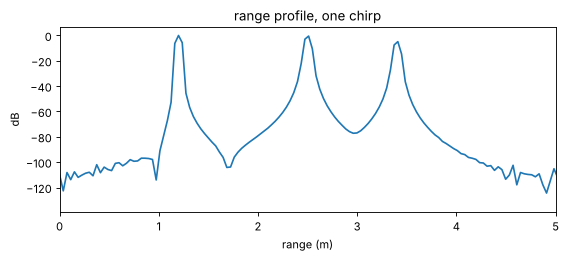

In [3]:
rp = np.abs(range_fft(data))[0, 0]
r_axis = np.arange(len(rp)) * radar.range_res
plt.figure(figsize=(8, 3)); plt.plot(r_axis, 20 * np.log10(rp + 1e-12)); plt.xlim(0, 5)
plt.xlabel("range (m)"); plt.ylabel("dB"); plt.title("range profile, one chirp"); plt.show()

## 3. Range-Doppler map

A second FFT across chirps gives radial velocity (chapter 9).

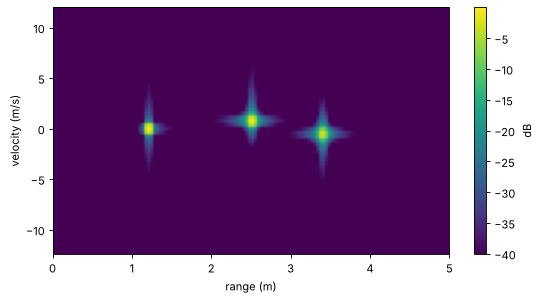

In [4]:
m, ranges, velocities, rd = rd_map(radar, data)
plt.figure(figsize=(8, 4)); plt.imshow(10 * np.log10(m + 1e-12), aspect="auto", origin="lower",
    extent=[ranges[0], ranges[-1], velocities[0], velocities[-1]], vmin=-40)
plt.xlim(0, 5); plt.xlabel("range (m)"); plt.ylabel("velocity (m/s)"); plt.colorbar(label="dB"); plt.show()

## 4. Angle from the virtual channels

For each peak cell, the 8 channel values form a snapshot; an FFT/Bartlett scan across them gives angle (chapters 11 and 15). Note: with TDM-MIMO, a moving target needs Doppler compensation first (chapter 15); the static target is exact.

In [5]:
ang = np.linspace(-90, 90, 721)
for t in targets:
    ir = int(np.argmin(np.abs(ranges - t.r))); iv = int(np.argmin(np.abs(velocities - t.v)))
    sp = angle_spectrum(rd[iv, :, ir], radar.virtual()[:, 0], ang)
    print(f"target at {t.r} m, {t.v:+.1f} m/s, true {t.az:+d} deg -> peak {ang[np.argmax(sp)]:+.1f} deg")

target at 1.2 m, +0.0 m/s, true -20 deg -> peak -20.0 deg
target at 2.5 m, +0.8 m/s, true +10 deg -> peak +10.2 deg
target at 3.4 m, -0.5 m/s, true +35 deg -> peak +34.8 deg


## Next

Each chapter has its own script in `examples/` (run with `--no-plot` for numbers only), e.g. `python examples/ch08_phase_precision.py` for micrometre ranging from phase, or `python examples/ch19_4d_point_cloud.py` for a full 4D point cloud.